# Pediatric Critical Care Analytics — Phase 3: Predictive Analytics

**Phase 1 (descriptive)** told us *what* happened. **Phase 2 (diagnostic)** told us *why* patterns
exist and which factors are statistically real drivers. **Phase 3 (this notebook)** asks: **can we
predict outcomes at admission, early enough to act on them?**

This is the layer that turns analytics into an operational tool — a mortality-risk score or LOS
forecast computed from the first 24 hours of an ICU stay is something a clinical team can actually
use at the bedside, not just something leadership reviews in a monthly report.

## What we're predicting
1. **In-hospital mortality risk**, using only data available in the first 24 hours of the ICU stay
   (a simplified, from-scratch version of what clinical severity scores like PIM3/PRISM do)
2. **ICU length of stay**, as a regression problem — useful for bed/capacity planning

## Data used
All 10 available PIC tables:
`PATIENTS`, `ADMISSIONS`, `ICUSTAYS`, `DIAGNOSES_ICD`, `D_ICD_DIAGNOSES`, `LABEVENTS`,
`D_LABITEMS`, `CHARTEVENTS`, `D_ITEMS`, `PRESCRIPTIONS`.

**Modeling unit:** one row per hospital admission (`HADM_ID`), using that admission's **first**
ICU stay if there were several. Features are built only from data occurring in the **first 24
hours after ICU admission** — this matters: using data from later in the stay (e.g. discharge
labs) would leak the outcome into the features and produce an unrealistically good but useless
model, since that data wouldn't exist yet at the point you'd actually want a prediction.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (roc_auc_score, roc_curve, average_precision_score,
                              confusion_matrix, classification_report,
                              mean_absolute_error, r2_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 60)

t0 = time.time()


In [2]:
admissions = pd.read_csv("ADMISSIONS.csv")
icustays = pd.read_csv("ICUSTAYS.csv")
patients = pd.read_csv("PATIENTS.csv")
diagnoses = pd.read_csv("DIAGNOSES_ICD.csv")
d_icd = pd.read_csv("D_ICD_DIAGNOSES.csv")
d_items = pd.read_csv("D_ITEMS.csv")
d_lab = pd.read_csv("D_LABITEMS.csv")

for col in ["ADMITTIME", "DISCHTIME", "DEATHTIME"]:
    admissions[col] = pd.to_datetime(admissions[col], format="%d-%m-%Y %H:%M", errors="coerce")
for col in ["INTIME", "OUTTIME"]:
    icustays[col] = pd.to_datetime(icustays[col], errors="coerce")
for col in ["DOB", "DOD"]:
    patients[col] = pd.to_datetime(patients[col], errors="coerce")

print(f"[{time.time()-t0:.1f}s] core + dictionary tables loaded")


[0.9s] core + dictionary tables loaded


## 1. Load core tables

## 2. Build the modeling cohort

One row per hospital admission, using the first ICU stay if a patient had multiple. Defines the
24-hour feature window, age, age group, and primary diagnosis chapter (same approach as Phase 2).


In [3]:
icu_first = icustays.sort_values(["HADM_ID", "INTIME"]).groupby("HADM_ID").first().reset_index()

cohort = (
    icu_first
    .merge(admissions, on=["SUBJECT_ID", "HADM_ID"], how="left")
    .merge(patients, on="SUBJECT_ID", how="left")
)
cohort["age_years"] = (cohort["ADMITTIME"] - cohort["DOB"]).dt.days / 365.25
cohort["los_icu_days"] = cohort["LOS"]
cohort["window_start"] = cohort["INTIME"]
cohort["window_end"] = cohort["INTIME"] + pd.Timedelta(hours=24)

def age_group(age):
    if pd.isna(age): return "Unknown"
    if age < 1/12: return "Neonate"
    elif age < 1: return "Infant"
    elif age < 3: return "Toddler"
    elif age < 12: return "Child"
    else: return "Adolescent"

cohort["age_group"] = cohort["age_years"].apply(age_group)

icd10_chapters = {
    "A": "Infectious", "B": "Infectious", "C": "Neoplasms", "D": "Blood/immune",
    "E": "Endocrine/metabolic", "F": "Mental/behavioural", "G": "Nervous system",
    "H": "Eye/ear", "I": "Circulatory", "J": "Respiratory", "K": "Digestive",
    "L": "Skin", "M": "Musculoskeletal", "N": "Genitourinary", "O": "Pregnancy/childbirth",
    "P": "Perinatal", "Q": "Congenital malformations", "R": "Symptoms/unclassified",
    "S": "Injury/poisoning", "T": "Injury/poisoning", "Z": "Health status/services",
}
diagnoses["chapter_code"] = diagnoses["ICD10_CODE_CN"].astype(str).str[0].str.upper()
diagnoses["chapter_name"] = diagnoses["chapter_code"].map(icd10_chapters).fillna("Other/uncoded")
primary_diag = (
    diagnoses.sort_values(["HADM_ID", "SEQ_NUM"]).groupby("HADM_ID").first()[["chapter_name"]]
    .rename(columns={"chapter_name": "primary_diagnosis_chapter"})
)
cohort = cohort.merge(primary_diag, on="HADM_ID", how="left")
cohort["primary_diagnosis_chapter"] = cohort["primary_diagnosis_chapter"].fillna("Not coded")

print(f"[{time.time()-t0:.1f}s] cohort built: {len(cohort):,} admissions "
      f"({cohort['HOSPITAL_EXPIRE_FLAG'].mean()*100:.2f}% mortality)")


[1.1s] cohort built: 13,449 admissions (7.22% mortality)


## 3. First-24h vital-sign features (from `CHARTEVENTS`)

We select 7 core vitals available in the dictionary (`D_ITEMS`) — temperature, pulse, heart rate,
respiratory rate, SpO2, and systolic/diastolic blood pressure — and compute min/max/mean for each
within the first 24 hours of the ICU stay. `CHARTEVENTS` has ~2.3M rows total, so we filter to the
relevant `ITEMID`s in chunks before loading fully into memory.


In [4]:
VITAL_IDS = {"1001": "temp", "1002": "pulse", "1003": "hr", "1004": "rr",
             "1006": "spo2", "1015": "dbp", "1016": "sbp"}

print("Vitals used (from D_ITEMS):")
display(d_items[d_items["ITEMID"].astype(str).isin(VITAL_IDS.keys())][["ITEMID", "LABEL", "UNITNAME"]])

chart_frames = []
for chunk in pd.read_csv("CHARTEVENTS.csv",
                          usecols=["SUBJECT_ID", "HADM_ID", "ICUSTAY_ID", "ITEMID", "CHARTTIME", "VALUENUM"],
                          dtype={"ITEMID": str}, chunksize=2_000_000):
    chart_frames.append(chunk[chunk["ITEMID"].isin(VITAL_IDS.keys())])
chart = pd.concat(chart_frames, ignore_index=True)
chart["CHARTTIME"] = pd.to_datetime(chart["CHARTTIME"], errors="coerce")
chart["vital_name"] = chart["ITEMID"].map(VITAL_IDS)

chart = chart.merge(cohort[["HADM_ID", "window_start", "window_end"]], on="HADM_ID", how="inner")
chart = chart[(chart["CHARTTIME"] >= chart["window_start"]) & (chart["CHARTTIME"] <= chart["window_end"])]

vitals_wide = (
    chart.groupby(["HADM_ID", "vital_name"])["VALUENUM"].agg(["min", "max", "mean"]).unstack("vital_name")
)
vitals_wide.columns = [f"{stat}_{name}" for stat, name in vitals_wide.columns]
vitals_wide = vitals_wide.reset_index()

print(f"[{time.time()-t0:.1f}s] vitals features built: {vitals_wide.shape[0]:,} admissions covered "
      f"({vitals_wide.shape[0]/len(cohort)*100:.1f}% of cohort), {vitals_wide.shape[1]-1} features")


Vitals used (from D_ITEMS):


,ITEMID,LABEL,UNITNAME
0,1001,Temperature,°C
1,1002,Pulse,bpm
2,1003,Heart Rate,bpm
3,1004,Respiratory Rate,insp/min
4,1006,Oxygen saturation,%
13,1015,Diastolic Pressure,mmHg
14,1016,Systolic Pressure,mmHg


[11.6s] vitals features built: 9,804 admissions covered (72.9% of cohort), 21 features


## 4. First-24h lab features (from `LABEVENTS`)

Same approach for 10 clinically standard severity-relevant labs — lactate, creatinine, pH, CRP,
hemoglobin, glucose, sodium, potassium, WBC count, and platelet count. `LABEVENTS` has ~10.1M rows,
so filtering to relevant `ITEMID`s first is essential for performance. We also count how many
**abnormal-flagged** results (`FLAG` = high/low) each admission had in the first 24 hours — a
simple severity proxy that doesn't require knowing clinical reference ranges ourselves, since the
flag was already computed by the source hospital's lab system.


In [5]:
LAB_IDS = {5227: "lactate", 5041: "creatinine", 5237: "ph", 5626: "crp",
           5257: "hemoglobin", 5223: "glucose", 5230: "sodium", 5226: "potassium",
           5141: "wbc", 5129: "platelet"}

print("Labs used (from D_LABITEMS):")
display(d_lab[d_lab["ITEMID"].isin(LAB_IDS.keys())][["ITEMID", "LABEL", "FLUID", "CATEGORY"]])

lab_frames = []
for chunk in pd.read_csv("LABEVENTS.csv",
                          usecols=["SUBJECT_ID", "HADM_ID", "ITEMID", "CHARTTIME", "VALUENUM", "FLAG"],
                          chunksize=2_000_000):
    lab_frames.append(chunk[chunk["ITEMID"].isin(LAB_IDS.keys())])
lab = pd.concat(lab_frames, ignore_index=True)
lab["CHARTTIME"] = pd.to_datetime(lab["CHARTTIME"], errors="coerce")
lab["lab_name"] = lab["ITEMID"].map(LAB_IDS)

lab = lab.merge(cohort[["HADM_ID", "window_start", "window_end"]], on="HADM_ID", how="inner")
lab = lab[(lab["CHARTTIME"] >= lab["window_start"]) & (lab["CHARTTIME"] <= lab["window_end"])]

labs_wide = (
    lab.groupby(["HADM_ID", "lab_name"])["VALUENUM"].agg(["min", "max", "mean"]).unstack("lab_name")
)
labs_wide.columns = [f"{stat}_{name}" for stat, name in labs_wide.columns]
labs_wide = labs_wide.reset_index()

abnormal_counts = (
    lab[lab["FLAG"].isin(["l", "h"])].groupby("HADM_ID").size()
    .rename("n_abnormal_labs_24h").reset_index()
)

print(f"[{time.time()-t0:.1f}s] lab features built: {labs_wide.shape[0]:,} admissions covered "
      f"({labs_wide.shape[0]/len(cohort)*100:.1f}% of cohort), {labs_wide.shape[1]-1} features")


Labs used (from D_LABITEMS):


,ITEMID,LABEL,FLUID,CATEGORY
29,5041,Creatinine,Blood,Chemistry
74,5129,Platelet Count,Blood,Hematology
77,5141,WBC Count,Blood,Hematology
135,5223,Glucose,Blood,Chemistry
138,5226,Potassium,Other Body Fluid,Blood Gas
139,5227,Lactate,Blood,Blood Gas
142,5230,"Sodium, Whole Blood",Blood,Blood Gas
148,5237,pH,Blood,Blood Gas
165,5257,Hemoglobin,Blood,Hematology
296,5626,C-Reactive Protein,Blood,Chemistry


[34.9s] lab features built: 12,267 admissions covered (91.2% of cohort), 30 features


## 5. Vasopressor/inotrope use flag (from `PRESCRIPTIONS`)

Whether a patient received a vasopressor or inotrope (norepinephrine, epinephrine, dopamine,
dobutamine, vasopressin) is one of the strongest treatment-intensity signals for critical illness
— a simple, powerful feature that doesn't require a full medication-timing model.


In [6]:
VASOPRESSOR_KEYWORDS = ["norepinephrine", "epinephrine", "dopamine", "dobutamine",
                        "vasopressin", "adrenaline"]

presc_frames = []
for chunk in pd.read_csv("PRESCRIPTIONS.csv",
                          usecols=["SUBJECT_ID", "HADM_ID", "DRUG_NAME_EN"], chunksize=2_000_000):
    mask = chunk["DRUG_NAME_EN"].astype(str).str.lower().str.contains(
        "|".join(VASOPRESSOR_KEYWORDS), na=False)
    presc_frames.append(chunk[mask])
vaso = pd.concat(presc_frames, ignore_index=True)
vaso_flag = vaso[["HADM_ID"]].drop_duplicates()
vaso_flag["received_vasopressor"] = 1

print(f"[{time.time()-t0:.1f}s] vasopressor flag built: {len(vaso_flag):,} admissions "
      f"({len(vaso_flag)/len(cohort)*100:.1f}% of cohort) received a vasopressor/inotrope at some point")


[41.5s] vasopressor flag built: 4,078 admissions (30.3% of cohort) received a vasopressor/inotrope at some point


## 6. Assemble the final feature matrix

In [7]:
features = (
    cohort[["HADM_ID", "age_years", "age_group", "GENDER", "FIRST_CAREUNIT",
            "primary_diagnosis_chapter", "HOSPITAL_EXPIRE_FLAG", "los_icu_days"]]
    .merge(vitals_wide, on="HADM_ID", how="left")
    .merge(labs_wide, on="HADM_ID", how="left")
    .merge(abnormal_counts, on="HADM_ID", how="left")
    .merge(vaso_flag, on="HADM_ID", how="left")
)
features["n_abnormal_labs_24h"] = features["n_abnormal_labs_24h"].fillna(0)
features["received_vasopressor"] = features["received_vasopressor"].fillna(0)

print(f"Final feature matrix: {features.shape[0]:,} admissions x {features.shape[1]} columns")
print(f"\nMissingness (top 10 columns with most missing values — expected, since not every "
      f"admission had every vital/lab drawn in the first 24h):")
display(features.isna().mean().sort_values(ascending=False).head(10).mul(100).round(1))

features.head()


Final feature matrix: 13,449 admissions x 61 columns

Missingness (top 10 columns with most missing values — expected, since not every admission had every vital/lab drawn in the first 24h):


min_pulse     73.9
mean_pulse    73.9
max_pulse     73.9
min_spo2      69.2
max_spo2      69.2
mean_spo2     69.2
max_dbp       62.4
mean_sbp      62.4
max_sbp       62.4
min_dbp       62.4
dtype: float64

,HADM_ID,age_years,age_group,GENDER,FIRST_CAREUNIT,primary_diagnosis_chapter,HOSPITAL_EXPIRE_FLAG,los_icu_days,min_dbp,min_hr,min_pulse,min_rr,min_sbp,min_spo2,min_temp,max_dbp,max_hr,max_pulse,max_rr,max_sbp,max_spo2,max_temp,mean_dbp,mean_hr,mean_pulse,mean_rr,mean_sbp,mean_spo2,mean_temp,min_creatinine,...,min_glucose,min_hemoglobin,min_lactate,min_ph,min_platelet,min_potassium,min_sodium,min_wbc,max_creatinine,max_crp,max_glucose,max_hemoglobin,max_lactate,max_ph,max_platelet,max_potassium,max_sodium,max_wbc,mean_creatinine,mean_crp,mean_glucose,mean_hemoglobin,mean_lactate,mean_ph,mean_platelet,mean_potassium,mean_sodium,mean_wbc,n_abnormal_labs_24h,received_vasopressor
0,100000,0.383299,Infant,F,General ICU,Digestive,0,4.6167,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
1,100001,7.071869,Child,F,General ICU,Circulatory,1,9.1771,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0
2,100002,2.852841,Toddler,F,General ICU,Injury/poisoning,0,7.7326,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0
3,100003,7.791923,Child,F,General ICU,Not coded,1,4.4132,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0
4,100004,0.933607,Infant,M,General ICU,Digestive,1,1.7479,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0


## 7. Model 1 — In-hospital mortality prediction

We compare a **logistic regression** (interpretable, coefficients show direction/magnitude of
each feature's effect) against a **random forest** (usually higher accuracy, captures
non-linear interactions, gives feature-importance ranking). Missing vitals/labs are median-imputed
— which itself is informative here, since a **missing** lab in the first 24h often means "this
patient wasn't sick enough to need that test," not random missingness.


In [8]:
target = "HOSPITAL_EXPIRE_FLAG"
categorical_cols = ["age_group", "GENDER", "FIRST_CAREUNIT", "primary_diagnosis_chapter"]
numeric_cols = [c for c in features.columns
                if pd.api.types.is_numeric_dtype(features[c])
                and c not in [target, "los_icu_days", "HADM_ID"]
                and c not in categorical_cols]

X = features[numeric_cols + categorical_cols]
y = features[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Train: {len(X_train):,} | Test: {len(X_test):,} | "
      f"Train mortality rate: {y_train.mean()*100:.2f}% | Test mortality rate: {y_test.mean()*100:.2f}%")

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                       ("scale", StandardScaler())]), numeric_cols),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                       ("ohe", OneHotEncoder(handle_unknown="ignore"))]), categorical_cols),
])

logit_pipe = Pipeline([("prep", preprocess),
                        ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
rf_pipe = Pipeline([("prep", preprocess),
                     ("clf", RandomForestClassifier(n_estimators=300, max_depth=8,
                                                     class_weight="balanced", random_state=42,
                                                     n_jobs=-1))])

logit_pipe.fit(X_train, y_train)
rf_pipe.fit(X_train, y_train)

logit_proba = logit_pipe.predict_proba(X_test)[:, 1]
rf_proba = rf_pipe.predict_proba(X_test)[:, 1]

print(f"\nLogistic Regression — ROC-AUC: {roc_auc_score(y_test, logit_proba):.3f}, "
      f"PR-AUC: {average_precision_score(y_test, logit_proba):.3f}")
print(f"Random Forest       — ROC-AUC: {roc_auc_score(y_test, rf_proba):.3f}, "
      f"PR-AUC: {average_precision_score(y_test, rf_proba):.3f}")


Train: 10,086 | Test: 3,363 | Train mortality rate: 7.22% | Test mortality rate: 7.23%

Logistic Regression — ROC-AUC: 0.840, PR-AUC: 0.308
Random Forest       — ROC-AUC: 0.880, PR-AUC: 0.415


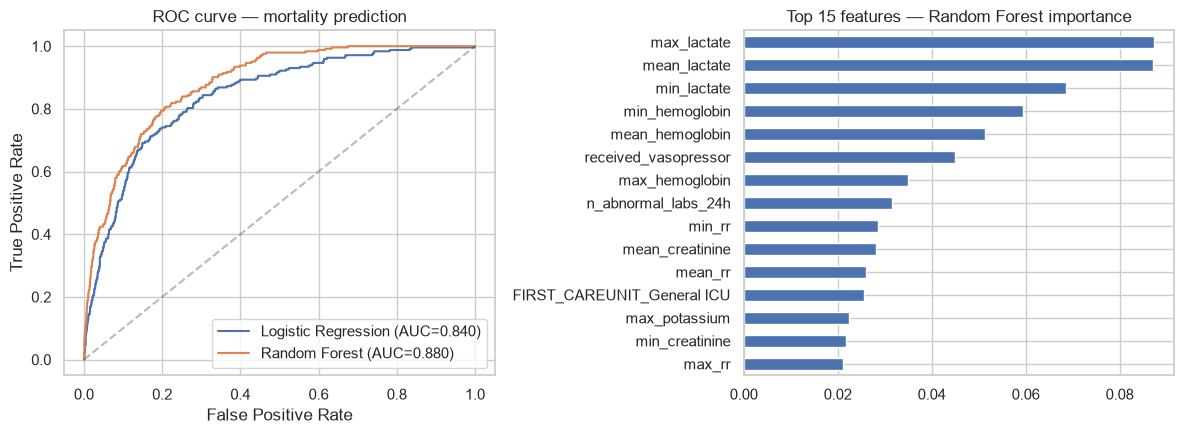

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name, proba in [("Logistic Regression", logit_proba), ("Random Forest", rf_proba)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC curve — mortality prediction")
axes[0].legend()

# Feature importance from Random Forest
ohe_cols = rf_pipe.named_steps["prep"].named_transformers_["cat"].named_steps["ohe"].get_feature_names_out(categorical_cols)
all_feature_names = numeric_cols + list(ohe_cols)
importances = rf_pipe.named_steps["clf"].feature_importances_
imp_series = pd.Series(importances, index=all_feature_names).sort_values(ascending=False).head(15)
imp_series.sort_values().plot(kind="barh", ax=axes[1], color="#4C72B0")
axes[1].set_title("Top 15 features — Random Forest importance")
plt.tight_layout()
plt.show()


**How to read this:** ROC-AUC of 0.5 = no better than a coin flip; 0.8+ is generally
considered strong discrimination in clinical risk models. Compare this against the crude,
unadjusted mortality-by-unit numbers from Phase 1/2 — this model combines *all* available signals
(age, diagnosis, vitals, labs, treatment intensity) into a single risk score, which is a
fundamentally different and more useful tool than looking at any one factor in isolation.

              precision    recall  f1-score   support

    Survived       0.97      0.86      0.91      3120
        Died       0.28      0.70      0.40       243

    accuracy                           0.85      3363
   macro avg       0.63      0.78      0.66      3363
weighted avg       0.92      0.85      0.87      3363



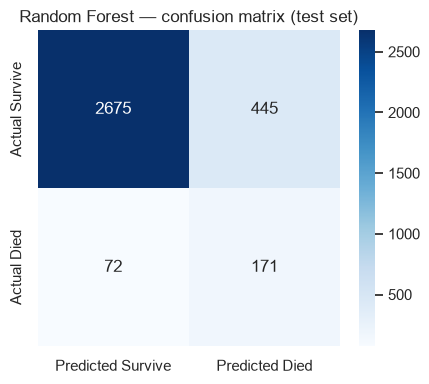

In [10]:
print(classification_report(y_test, rf_pipe.predict(X_test), target_names=["Survived", "Died"]))

cm = confusion_matrix(y_test, rf_pipe.predict(X_test))
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["Predicted Survive", "Predicted Died"],
            yticklabels=["Actual Survive", "Actual Died"])
ax.set_title("Random Forest — confusion matrix (test set)")
plt.tight_layout()
plt.show()


## 8. Model 2 — ICU length-of-stay prediction (regression)

Same feature set, predicting `los_icu_days` directly. Useful for **bed-capacity forecasting**:
if a hospital can estimate expected LOS at admission, it can plan discharges and incoming demand
more proactively rather than reactively.


Random Forest LOS regression — MAE: 7.14 days, R²: 0.223


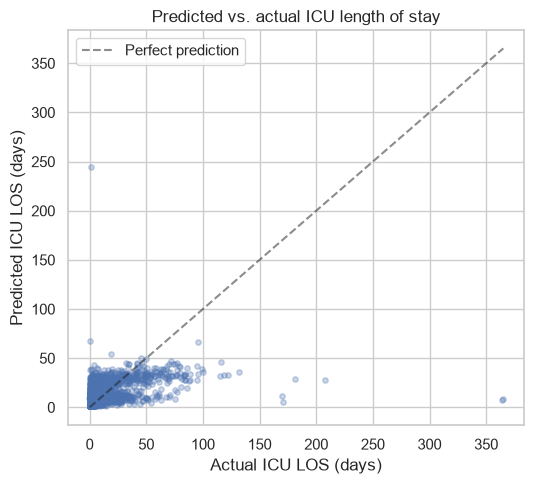

In [11]:
y_los = features["los_icu_days"]
mask = y_los.notna()
X_los, y_los = X[mask], y_los[mask]

X_train_los, X_test_los, y_train_los, y_test_los = train_test_split(
    X_los, y_los, test_size=0.25, random_state=42
)

rf_reg_pipe = Pipeline([("prep", preprocess),
                         ("reg", RandomForestRegressor(n_estimators=300, max_depth=8,
                                                        random_state=42, n_jobs=-1))])
rf_reg_pipe.fit(X_train_los, y_train_los)
los_pred = rf_reg_pipe.predict(X_test_los)

mae = mean_absolute_error(y_test_los, los_pred)
r2 = r2_score(y_test_los, los_pred)
print(f"Random Forest LOS regression — MAE: {mae:.2f} days, R²: {r2:.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test_los, los_pred, alpha=0.3, s=15, color="#4C72B0")
max_val = max(y_test_los.max(), los_pred.max())
ax.plot([0, max_val], [0, max_val], "k--", alpha=0.5, label="Perfect prediction")
ax.set_xlabel("Actual ICU LOS (days)")
ax.set_ylabel("Predicted ICU LOS (days)")
ax.set_title("Predicted vs. actual ICU length of stay")
ax.legend()
plt.tight_layout()
plt.show()


In [12]:
features.to_pickle("features_admission_level.pkl")